In [ ]:
# ── EDIT THIS CELL ───────────────────────────────────────────────────────────
CSV_PATH       = "Platformless.csv"
EXCEL_OUT      = "Plant.xlsx"
LOG            = False
SOLVER_LOG     = False   # set True only to debug OR-Tools internals
MAX_SOLVE_SECS = 60      # ignored when RUN_TO_OPTIMAL = True
RUN_TO_OPTIMAL = False   # True = run until gap is 0% (no time limit)
WORKERS        = 8
FILL_SIZE      = 2       # size of fill extras: 2 = 2x2, 3 = 3x3

structures = {4: 3,  3: 8, 2: 0,  1: 10}
# structures = {4: 0,  3: 0, 2: 0,  1: 0}
monsters = {4: 1*3+10, 3: 1*3  , 2: 14*3+3+7, 1: 3*3+42} # Plant
# monsters = {4: 1*3+7,  3: 3*3  , 2: 12*3+3, 1: 3*3+70} # Cold
# monsters = {4: 1*3+8,  3: 2*3  , 2: 16*3+2, 1: 1*3+70} # Air
# monsters = {4: 1*3+6,  3: 4*3+1, 2: 12*3+2, 1: 2*3+70} # Water
# monsters = {4: 1*3+10,  3: 1*3  , 2: 13*3+2, 1: 4*3+70} # Earth
# monsters = {4: 1*3+6,  3: 2*3  , 2: 14*3+1, 1: 2*3+70} # Haven
# monsters = {4: 0,  3: 3*3  , 2: 10*3, 1: 0} # Crystal

In [14]:
# ── Imports, helpers, CSV loader ─────────────────────────────────────────────
import csv
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import Counter, defaultdict
from dataclasses import dataclass
from datetime import datetime
from ortools.sat.python import cp_model

DISPLAY_COLORS = {
    "blocked":   "#2B2B2B",
    "empty":     "#FFFFFF",
    "structure": "#4C78A8",
    "monster":   "#E45756",
    "extra":     "#54A24B",
}

def _ts() -> str:
    return datetime.now().strftime("%H:%M:%S")

def log_print(enabled: bool, msg: str) -> None:
    if enabled:
        print(f"[{_ts()}] {msg}", flush=True)

def load_avail_from_csv(path: str, log: bool = True) -> np.ndarray:
    t0 = time.time()
    log_print(log, f"Loading CSV: {path}")
    rows = []
    with open(path, "r", encoding="utf-8-sig", newline="") as f:
        for r in csv.reader(f):
            if r and not all(str(x).strip() == "" for x in r):
                rows.append([str(x).strip() for x in r])
    if not rows:
        raise ValueError("CSV is empty.")
    W = max(len(r) for r in rows)
    rows = [r + ["#"] * (W - len(r)) for r in rows]
    H = len(rows)
    _true  = {".", "1", "true", "t", "yes", "y", "avail", "available"}
    _false = {"#", "0", "false", "f", "no", "n", "", "blocked", "x", "na", "n/a"}
    def to_bool(v: str) -> bool:
        v = v.strip().lower()
        if v in _true:  return True
        if v in _false: return False
        raise ValueError(f"Unknown cell value '{v}'.")
    avail = np.zeros((H, W), dtype=bool)
    for y in range(H):
        for x in range(W):
            avail[y, x] = to_bool(rows[y][x])
    log_print(log, f"Loaded {W}x{H} | available={int(avail.sum())} | {time.time()-t0:.2f}s")
    return avail

In [15]:
# ── Solver ───────────────────────────────────────────────────────────────────
@dataclass(frozen=True)
class Placement:
    x: int; y: int; s: int; kind: str; group: str


def _valid_topleft(avail: np.ndarray, s: int, log: bool = False, label: str = "") -> list:
    H, W = avail.shape
    if H < s or W < s:
        return []
    t0 = time.time()
    blocked = (~avail).astype(np.int16)
    sat = np.pad(blocked, ((1, 0), (1, 0)), mode="constant").cumsum(0).cumsum(1)
    bad = sat[s:, s:] - sat[:-s, s:] - sat[s:, :-s] + sat[:-s, :-s]
    ys, xs = np.where(bad == 0)
    coords = list(zip(xs.tolist(), ys.tolist()))
    if log:
        log_print(True, f"   {label}{s}x{s}: {len(coords)} positions | {time.time()-t0:.2f}s")
    return coords


def _gradient_scores(H: int) -> dict:
    # structures all target the top; monsters use size-based tiers
    targets = {
        "structure": {4: 0.05, 3: 0.12, 2: 0.20, 1: 0.28},
        "monster":   {4: 0.10, 3: 0.32, 2: 0.66, 1: 0.92},
        "extra":     {4: 0.10, 3: 0.32, 2: 0.66, 1: 0.92},
    }
    weight = {4: 6, 3: 4, 2: 2, 1: 1}
    max_d  = max(1.0, H - 1)
    out = {}
    for group, t_map in targets.items():
        for s in [1, 2, 3, 4]:
            t = t_map[s] * (H - 1)
            for y in range(H):
                out[(group, s, y)] = int(round(weight[s] * 1000 * (max_d - abs(y + (s - 1) / 2 - t))))
    return out


def _band_filter(coords, *, s, H, lo, hi):
    lo_y, hi_y = lo * (H - 1), hi * (H - 1)
    return [(x, y) for x, y in coords if lo_y <= y + (s - 1) / 2 <= hi_y]


def _band_candidates(coords, *, s, H, required, log, lo=None, hi=None):
    if required <= 0:
        return []
    default = {4: (0.0, 0.75), 3: (0.0, 1.0), 2: (0.0, 1.0), 1: (0.0, 1.0)}
    lo = default[s][0] if lo is None else lo
    hi = default[s][1] if hi is None else hi
    step = 0.06
    while True:
        filtered = _band_filter(coords, s=s, H=H, lo=lo, hi=hi)
        if len(filtered) >= required:
            if log:
                log_print(True, f"   band {s}x{s}: {len(filtered)} in [{lo:.2f},{hi:.2f}]")
            return filtered
        if lo <= 0.0 and hi >= 1.0:
            return filtered
        lo = max(0.0, lo - step); hi = min(1.0, hi + step)


# top-biased initial bands for structures (relax automatically if grid is too small)
_STRUCT_BANDS = {4: (0.0, 0.40), 3: (0.0, 0.50), 2: (0.0, 0.60), 1: (0.0, 0.70)}


def solve_full_collection_with_fill(
    avail, structures, monsters, *,
    log=True, solver_log=False, workers=8, max_time_in_seconds=None, fill_size=2,
):
    t_start = time.time()
    H, W = avail.shape
    avail_cells = int(avail.sum())
    all_pos = [(x, y) for y in range(H) for x in range(W) if avail[y, x]]

    sc  = {s: int(structures.get(s, 0)) for s in [1, 2, 3, 4]}
    mc  = {s: int(monsters.get(s,   0)) for s in [1, 2, 3, 4]}
    req = {s: sc[s] + mc[s]             for s in [1, 2, 3, 4]}

    for lbl, d in [("structures", sc), ("monsters", mc)]:
        for s, c in d.items():
            if c < 0: raise ValueError(f"{lbl}[{s}] must be >= 0.")
    if sum(req[s] * s * s for s in [1, 2, 3, 4]) > avail_cells:
        return {"ok": False, "reason": "Required cells exceed available cells."}

    log_print(log, f"Grid {W}x{H} | avail={avail_cells} | structs={sc} | monsters={mc} | totals={req}")
    model  = cp_model.CpModel()
    scores = _gradient_scores(H)

    # raw candidate positions per size (shared; band-filtering per group below)
    raw = {s: _valid_topleft(avail, s, log=log) for s in [2, 3, 4] if req[s] > 0}

    # mandatory vars (2x2 – 4x4): structures get top-biased band, monsters use defaults
    mand_vars = {}
    for group, counts in [("structure", sc), ("monster", mc)]:
        for s in [4, 3, 2]:
            if counts[s] == 0: continue
            r = raw.get(s, [])
            if group == "structure":
                lo, hi = _STRUCT_BANDS[s]
                pool = _band_candidates(r, s=s, H=H, required=counts[s], log=log, lo=lo, hi=hi)
            else:
                pool = _band_candidates(r, s=s, H=H, required=counts[s], log=log)
            if not pool:
                return {"ok": False, "reason": f"No placement for {group} {s}x{s}."}
            v_map = {pos: model.NewBoolVar(f"{group[0]}{s}_{pos[0]}_{pos[1]}") for pos in pool}
            mand_vars[(group, s)] = v_map
            model.Add(sum(v_map.values()) == counts[s])
            log_print(log, f"   {group} {s}x{s}: {len(v_map)} cands | req={counts[s]}")

    # 1x1 vars: structures top-biased, monsters default
    one_vars = {}
    for group, cnt in [("structure", sc[1]), ("monster", mc[1])]:
        if cnt > avail_cells:
            return {"ok": False, "reason": f"{group} 1x1={cnt} > avail={avail_cells}."}
        if group == "structure":
            lo, hi = _STRUCT_BANDS[1]
            banded = _band_candidates(all_pos, s=1, H=H, required=cnt, log=log, lo=lo, hi=hi)
        else:
            banded = _band_candidates(all_pos, s=1, H=H, required=cnt, log=log)
        v_map = {pos: model.NewBoolVar(f"{group[0]}1_{pos[0]}_{pos[1]}") for pos in banded}
        one_vars[group] = v_map
        model.Add(sum(v_map.values()) == cnt)
        log_print(log, f"   {group} 1x1: {len(v_map)} cands | req={cnt}")

    # fill NxN vars
    fill_pos  = _valid_topleft(avail, fill_size, log=log, label=f"fill ")
    fill_vars = {pos: model.NewBoolVar(f"f{fill_size}_{pos[0]}_{pos[1]}") for pos in fill_pos}

    # non-overlap: at most one piece per cell
    cover = defaultdict(list)
    for (group, s), v_map in mand_vars.items():
        for (tx, ty), v in v_map.items():
            for dy in range(s):
                for dx in range(s):
                    cover[(ty + dy, tx + dx)].append(v)
    for (tx, ty), v in fill_vars.items():
        for dy in range(fill_size):
            for dx in range(fill_size):
                cover[(ty + dy, tx + dx)].append(v)
    for x, y in all_pos:
        terms = list(cover[(y, x)])
        sv = one_vars["structure"].get((x, y))
        mv = one_vars["monster"].get((x, y))
        if sv is not None: terms.append(sv)
        if mv is not None: terms.append(mv)
        if terms: model.Add(sum(terms) <= 1)

    # objective: maximise fill NxN (primary), then gradient (secondary)
    fill_obj  = sum(fill_vars.values())
    sec_terms = []
    for (group, s), v_map in mand_vars.items():
        for (x, y), v in v_map.items():
            sec_terms.append(scores[(group, s, y)] * v)
    for group in ["structure", "monster"]:
        for (x, y), v in one_vars[group].items():
            sec_terms.append(scores[(group, 1, y)] * v)
    for (x, y), v in fill_vars.items():
        sec_terms.append(scores[("extra", fill_size, y)] * v)

    n_vars    = sum(len(v) for v in mand_vars.values()) + sum(len(v) for v in one_vars.values()) + len(fill_vars)
    max_score = max(scores.values()) if scores else 1
    pw = n_vars * max_score + 1
    model.Maximize(pw * fill_obj + sum(sec_terms))

    solver = cp_model.CpSolver()
    solver.parameters.num_search_workers  = int(workers)
    solver.parameters.log_search_progress = bool(solver_log)
    if max_time_in_seconds is not None:
        solver.parameters.max_time_in_seconds = float(max_time_in_seconds)
    status      = solver.Solve(model)
    status_name = solver.StatusName(status)
    log_print(log, f"Solver: {status_name}")

    if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return {"ok": False, "status": status_name, "reason": status_name}

    placements = []
    for (group, s), v_map in mand_vars.items():
        for (x, y), v in v_map.items():
            if solver.Value(v): placements.append(Placement(x, y, s, f"{group}_{s}x{s}", group))
    for group in ["structure", "monster"]:
        for (x, y), v in one_vars[group].items():
            if solver.Value(v): placements.append(Placement(x, y, 1, f"{group}_1x1", group))
    fill_count = 0
    for (x, y), v in fill_vars.items():
        if solver.Value(v):
            placements.append(Placement(x, y, fill_size, f"extra_{fill_size}x{fill_size}", "extra"))
            fill_count += 1

    obj_val    = solver.ObjectiveValue()
    best_bound = solver.BestObjectiveBound()
    log_print(log, f"Done | fill_{fill_size}x{fill_size}={fill_count} | {time.time()-t_start:.2f}s")
    return {
        "ok": True, "status": status_name, "optimal": status == cp_model.OPTIMAL,
        "W": W, "H": H, "available_cells": avail_cells,
        "structures": sc, "monsters": mc, "required_totals": req,
        "fill_size": fill_size, "fill_count": fill_count,
        "objective_value": obj_val, "best_objective_bound": best_bound,
        "relative_gap": None if obj_val == 0 else (best_bound - obj_val) / abs(obj_val),
        "solve_wall_time_seconds": solver.WallTime(),
        "placements": placements,
    }

In [16]:
# ── Visualization + Export ───────────────────────────────────────────────────
def draw_solution(avail: np.ndarray, sol: dict):
    H, W = avail.shape
    fs = sol["fill_size"]
    bg = np.where(avail[:, :, np.newaxis], [1.0, 1.0, 1.0], [43/255, 43/255, 43/255])
    fig, ax = plt.subplots(figsize=(max(12, W / 2.2), max(10, H / 2.2)))
    ax.imshow(bg, interpolation="none", origin="upper")
    for p in sol["placements"]:
        ax.add_patch(mpatches.FancyBboxPatch(
            (p.x - 0.5, p.y - 0.5), p.s, p.s,
            boxstyle="square,pad=0",
            facecolor=DISPLAY_COLORS[p.group], edgecolor="#111111", linewidth=1.2, alpha=0.82,
        ))
        if p.s >= 2:
            ax.text(p.x + (p.s-1)/2, p.y + (p.s-1)/2, str(p.s),
                    ha="center", va="center", fontsize=max(8, 8+p.s),
                    color="white", fontweight="bold")
    ax.set_title(
        f"OPTIMAL Layout  —  blue=structure   red=monster   green=extra {fs}x{fs}\n"
        f"extra {fs}x{fs}: {sol['fill_count']}",
        pad=16,
    )
    ax.set_xlim(-0.5, W - 0.5); ax.set_ylim(H - 0.5, -0.5)
    ax.set_xticks(np.arange(-0.5, W, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, H, 1), minor=True)
    ax.grid(which="minor", color="#DDDDDD", linewidth=0.35)
    ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
    ax.legend(
        handles=[mpatches.Patch(color=DISPLAY_COLORS[g], label=g.capitalize())
                 for g in ["structure", "monster", "extra", "blocked"]],
        loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=4, frameon=False,
    )
    plt.tight_layout()
    plt.show()


def export_solution_to_excel(avail: np.ndarray, sol: dict, out_path: str = "solution.xlsx"):
    try:
        import openpyxl
        from openpyxl.styles import PatternFill
        from openpyxl.utils import get_column_letter
    except ImportError:
        raise ImportError("pip install openpyxl")
    H, W = avail.shape
    size_layer  = np.where(avail, 0, -1).astype(int)
    group_layer = np.where(avail, "empty", "blocked").astype(object)
    for p in sol["placements"]:
        size_layer [p.y:p.y+p.s, p.x:p.x+p.s] = p.s
        group_layer[p.y:p.y+p.s, p.x:p.x+p.s] = p.group
    colors = {
        ("blocked",-1):"FF2B2B2B", ("empty",0):"FFFFFFFF",
        ("structure",1):"FFDCE8F5",("structure",2):"FFA9C4E2",
        ("structure",3):"FF6F9FD1",("structure",4):"FF3E79B2",
        ("monster",1): "FFF8D6D6",("monster",2): "FFF2A7A7",
        ("monster",3): "FFE46F6F",("monster",4): "FFD64545",
        ("extra",1):   "FFD9F0D2",("extra",2):   "FFA9D99B",
        ("extra",3):   "FF78C266",("extra",4):   "FF4AA64A",
    }
    wb = openpyxl.Workbook()
    ws = wb.active; ws.title = "solution"
    for y in range(H):
        ws.row_dimensions[y+1].height = 18
        for x in range(W):
            c = colors[(group_layer[y, x], int(size_layer[y, x]))]
            cell = ws.cell(row=y+1, column=x+1)
            cell.fill = PatternFill(start_color=c, end_color=c, fill_type="solid")
    for x in range(W):
        ws.column_dimensions[get_column_letter(x+1)].width = 4
    wb.save(out_path)
    print(f"Saved: {out_path}")

In [17]:
# 10*750855+29*408799 > 11*750855+25*408799
# 40*3+1*3+1+17

Status: OPTIMAL  |  Optimal: True
Solve time: 46.210s  |  Gap: 0.00%
Structures verified: {1: 0, 2: 0, 3: 0, 4: 0}
Monsters verified:   {1: 0, 2: 30, 3: 9, 4: 0}
Fill 2x2: 43


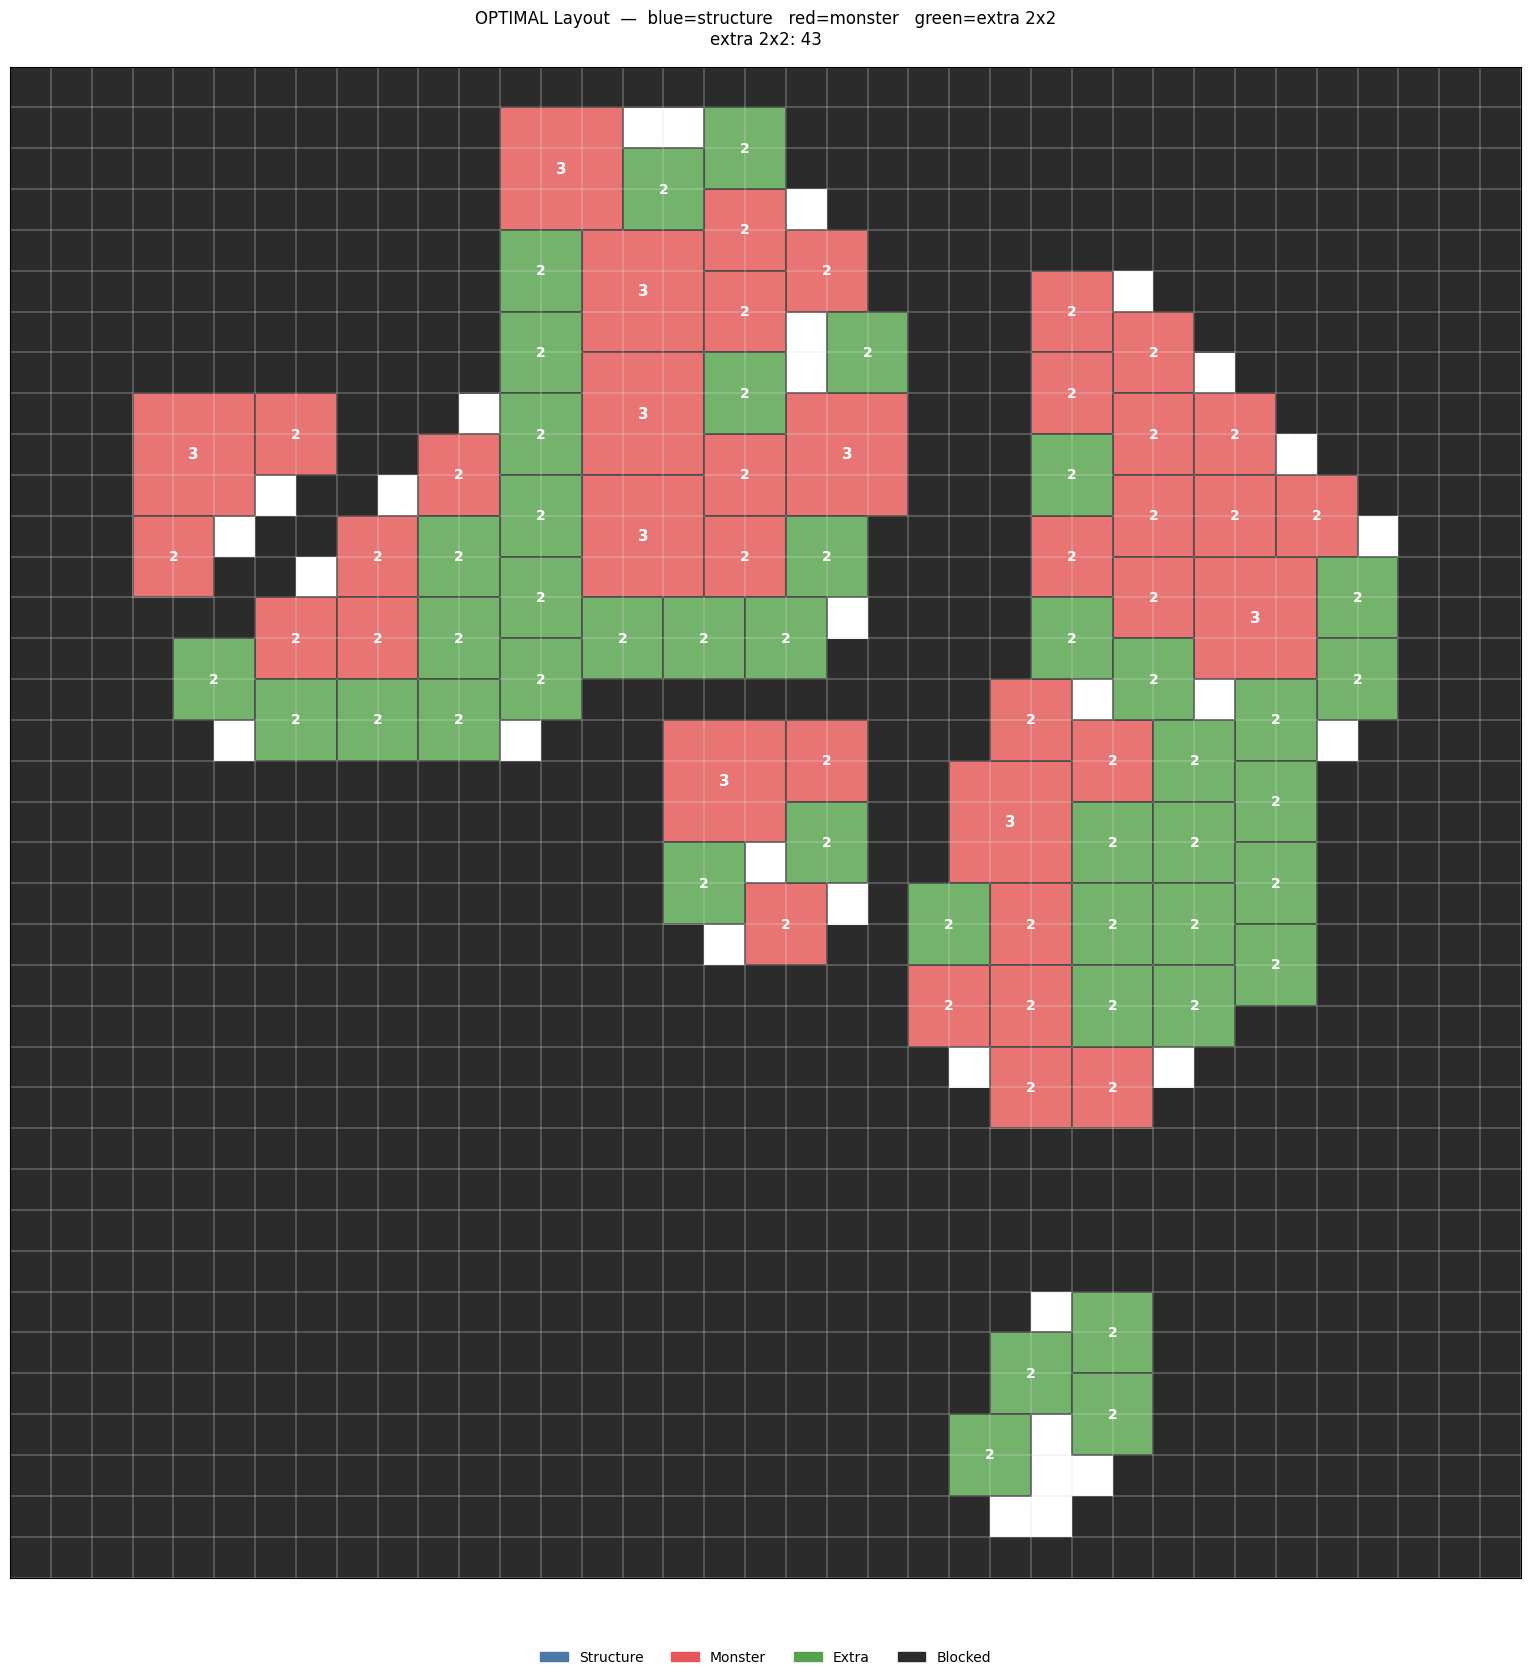

Saved: Crystal.xlsx


In [18]:
# ── Run (no editing needed) ───────────────────────────────────────────────────
avail = load_avail_from_csv(CSV_PATH, log=LOG)

sol = solve_full_collection_with_fill(
    avail, structures, monsters,
    log=LOG, solver_log=SOLVER_LOG,
    workers=WORKERS,
    max_time_in_seconds=None if RUN_TO_OPTIMAL else MAX_SOLVE_SECS,
    fill_size=FILL_SIZE,
)

if not sol["ok"]:
    print("FAILED:", sol.get("reason", sol.get("status")))
else:
    # validate counts
    tally = {g: Counter() for g in ["structure", "monster", "extra"]}
    for p in sol["placements"]: tally[p.group][p.s] += 1
    bd = {g: {s: int(tally[g][s]) for s in [1, 2, 3, 4]} for g in tally}

    exp_s = {s: int(structures.get(s, 0)) for s in [1, 2, 3, 4]}
    exp_m = {s: int(monsters.get(s,   0)) for s in [1, 2, 3, 4]}
    assert bd["structure"] == exp_s, f"Structure mismatch: {bd['structure']} != {exp_s}"
    assert bd["monster"]   == exp_m, f"Monster mismatch: {bd['monster']} != {exp_m}"

    # print summary
    fs  = sol["fill_size"]
    gap = sol["relative_gap"]
    gap_str = f"{gap:.2%}" if gap is not None else "n/a"
    print(f"Status: {sol['status']}  |  Optimal: {sol['optimal']}")
    print(f"Solve time: {sol['solve_wall_time_seconds']:.3f}s  |  Gap: {gap_str}")
    print(f"Structures verified: {bd['structure']}")
    print(f"Monsters verified:   {bd['monster']}")
    print(f"Fill {fs}x{fs}: {sol['fill_count']}")

    draw_solution(avail, sol)
    export_solution_to_excel(avail, sol, EXCEL_OUT)